# BTS Flight Delay EDA

Descriptive analysis of every monthly CSV currently available in `data/bronze/bts`,
including training, validation, and test periods. All rows are included; the loader
selects the schedule, identity, quality, and target columns used below.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [2]:
columns = [
    'Reporting_Airline', 'Origin', 'Dest', 'FlightDate',
    'CRSDepTime', 'CRSArrTime', 'Distance', 'CRSElapsedTime',
    'Flight_Number_Reporting_Airline', 'Cancelled', 'Diverted', 'ArrDel15'
]
str_cols = [
    'Reporting_Airline', 'Origin', 'Dest',
    'Flight_Number_Reporting_Airline', 'CRSDepTime', 'CRSArrTime'
]

root = Path.cwd()
if not (root / 'config.json').is_file():
    root = root.parent
bronze = root / 'data/bronze/bts'
csv_files = sorted(bronze.rglob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'No BTS CSV files found in {bronze}')

frames, inventory = [], []
for path in csv_files:
    frame = pd.read_csv(
        path, usecols=columns, dtype={col: 'category' for col in str_cols},
        parse_dates=['FlightDate'], keep_default_na=False, na_values=[''],
    )
    frames.append(frame)
    inventory.append({
        'file': path.relative_to(bronze).as_posix(),
        'rows': len(frame), 'first_date': frame['FlightDate'].min(),
        'last_date': frame['FlightDate'].max(), 'size_mb': path.stat().st_size / 1024**2,
    })
    print(f'{path.relative_to(bronze)}: {len(frame):,} rows')

# Preserve compact categories even when airlines/airports differ between files.
raw = pd.concat([frame.drop(columns=str_cols) for frame in frames], ignore_index=True)
for column in str_cols:
    raw[column] = pd.api.types.union_categoricals(
        [frame[column].array for frame in frames], sort_categories=True,
    ).as_ordered()
raw = raw[columns]
del frames, frame
file_summary = pd.DataFrame(inventory)
raw.head()


2024\01\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_1.csv: 547,271 rows


2024\02\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_2.csv: 519,221 rows


2024\03\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_3.csv: 591,767 rows


2024\04\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_4.csv: 582,185 rows


2024\05\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_5.csv: 609,743 rows


2024\06\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_6.csv: 611,132 rows


... (4 outputs left out)

2024\11\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_11.csv: 575,404 rows


2024\12\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_12.csv: 590,581 rows


2025\01\On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_1.csv: 539,747 rows


,Reporting_Airline,Origin,Dest,FlightDate,CRSDepTime,CRSArrTime,Distance,CRSElapsedTime,Flight_Number_Reporting_Airline,Cancelled,Diverted,ArrDel15
0,9E,LGA,OMA,2024-01-08,0856,1135,1148.0,219.0,4801,0.0,0.0,0.0
1,9E,LGA,OMA,2024-01-09,0856,1135,1148.0,219.0,4801,0.0,0.0,0.0
2,9E,LGA,OMA,2024-01-10,0856,1135,1148.0,219.0,4801,0.0,0.0,0.0
3,9E,LGA,OMA,2024-01-11,0856,1135,1148.0,219.0,4801,0.0,0.0,1.0
4,9E,LGA,OMA,2024-01-12,0856,1135,1148.0,219.0,4801,0.0,0.0,0.0


In [3]:
# Dataset summary: all discovered files and every row.
display(pd.Series({
    'monthly_files': len(csv_files),
    'total_rows': len(raw),
    'analysis_columns': len(raw.columns),
    'first_flight_date': raw['FlightDate'].min(),
    'last_flight_date': raw['FlightDate'].max(),
    'calendar_months': raw['FlightDate'].dt.to_period('M').nunique(),
    'airlines': raw['Reporting_Airline'].nunique(),
    'origin_airports': raw['Origin'].nunique(),
    'destination_airports': raw['Dest'].nunique(),
    'source_size_gb': file_summary['size_mb'].sum() / 1024,
    'loaded_memory_gb': raw.memory_usage(deep=True).sum() / 1024**3,
}).to_frame('value'))

print('Monthly file coverage')
display(file_summary.round({'size_mb': 1}))
print('Numeric statistics across all raw flight records (nulls excluded)')
display(raw.select_dtypes(include='number').describe().round(2).T)


,value
monthly_files,13
total_rows,7618808
analysis_columns,12
first_flight_date,2024-01-01 00:00:00
last_flight_date,2025-01-31 00:00:00
calendar_months,13
airlines,15
origin_airports,348
destination_airports,348
source_size_gb,3.208467


Monthly file coverage


,file,rows,first_date,last_date,size_mb
0,2024/01/On_Time_Reporting_Carrier_On_Time_Perf...,547271,2024-01-01,2024-01-31,235.4
1,2024/02/On_Time_Reporting_Carrier_On_Time_Perf...,519221,2024-02-01,2024-02-29,223.5
2,2024/03/On_Time_Reporting_Carrier_On_Time_Perf...,591767,2024-03-01,2024-03-31,255.3
3,2024/04/On_Time_Reporting_Carrier_On_Time_Perf...,582185,2024-04-01,2024-04-30,251.0
4,2024/05/On_Time_Reporting_Carrier_On_Time_Perf...,609743,2024-05-01,2024-05-31,263.6
5,2024/06/On_Time_Reporting_Carrier_On_Time_Perf...,611132,2024-06-01,2024-06-30,264.0
6,2024/07/On_Time_Reporting_Carrier_On_Time_Perf...,634613,2024-07-01,2024-07-31,274.2
7,2024/08/On_Time_Reporting_Carrier_On_Time_Perf...,619025,2024-08-01,2024-08-31,267.0
8,2024/09/On_Time_Reporting_Carrier_On_Time_Perf...,582622,2024-09-01,2024-09-30,250.8
9,2024/10/On_Time_Reporting_Carrier_On_Time_Perf...,615497,2024-10-01,2024-10-31,265.1


Numeric statistics across all raw flight records (nulls excluded)


,count,mean,std,min,25%,50%,75%,max
Distance,7618808.0,834.57,596.46,11.0,399.0,680.0,1069.0,5095.0
CRSElapsedTime,7618807.0,147.10,72.50,-160.0,94.0,130.0,178.0,1326.0
Cancelled,7618808.0,0.01,0.12,0.0,0.0,0.0,0.0,1.0
Diverted,7618808.0,0.00,0.05,0.0,0.0,0.0,0.0,1.0
ArrDel15,7487516.0,0.21,0.40,0.0,0.0,0.0,0.0,1.0


In [4]:
raw.dtypes.to_frame('dtype')

,dtype
Reporting_Airline,category
Origin,category
Dest,category
FlightDate,datetime64[ns]
CRSDepTime,category
CRSArrTime,category
Distance,float64
CRSElapsedTime,float64
Flight_Number_Reporting_Airline,category
Cancelled,float64


## Data Quality


In [5]:
df = raw.copy()
df['DepHour'] = (pd.to_numeric(df['CRSDepTime'], errors='coerce') // 100) % 24
df['DayOfWeek'] = df['FlightDate'].dt.dayofweek + 1

# Missing values
missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2)
})
display(missing[missing['missing'] > 0])



,missing,missing_pct
CRSElapsedTime,1,0.00
Flight_Number_Reporting_Airline,1,0.00
ArrDel15,131292,1.72


In [6]:
# Integrity checks
key = ['FlightDate', 'Reporting_Airline', 'Flight_Number_Reporting_Airline', 'Origin', 'Dest', 'CRSDepTime']
display(pd.Series({
    'duplicate_rows': df.duplicated().sum(),
    'repeated_keys': df[key].dropna().duplicated().sum(),
    'incomplete_keys': df[key].isna().any(axis=1).sum(),
    'invalid_distance_or_duration': ((df['Distance'] <= 0) | (df['CRSElapsedTime'] <= 0)).sum()
}))


duplicate_rows                  0
repeated_keys                   0
incomplete_keys                 1
invalid_distance_or_duration    1
dtype: int64

In [7]:
# Text and identifier ranges use alphabetical order.
display(df.apply(lambda column: column.dropna().agg(['min', 'max'])).T)


,min,max
Reporting_Airline,9E,YX
Origin,ABE,YUM
Dest,ABE,YUM
FlightDate,2024-01-01 00:00:00,2025-01-31 00:00:00
CRSDepTime,0001,2400
CRSArrTime,0001,2359
Distance,11.0,5095.0
CRSElapsedTime,-160.0,1326.0
Flight_Number_Reporting_Airline,1,999
Cancelled,0.0,1.0


## Analysing ArrDel15


In [8]:
# Filter to non-cancelled, non-diverted flights with a valid delay label
normal = df['Cancelled'].eq(0) & df['Diverted'].eq(0) & df['ArrDel15'].isin([0, 1])
flights = df.loc[normal].copy()

display(pd.Series({
    'raw_flights': len(df),
    'cancelled': df['Cancelled'].eq(1).sum(),
    'diverted': df['Diverted'].eq(1).sum(),
    'missing_target': df['ArrDel15'].isna().sum(),
    'valid_flights': len(flights)
}).to_frame('count'))

pd.crosstab(df['Cancelled'], df['ArrDel15'].isna(), rownames=['Cancelled'], colnames=['Target Missing'])


,count
raw_flights,7618808
cancelled,112627
diverted,18665
missing_target,131292
valid_flights,7487516


Target Missing,False,True
Cancelled,,
0.0,7487516,18665
1.0,0,112627


## ArrDel15 Distribution


,count,pct
ArrDel15,,
0.0,5939420,79.32
1.0,1548096,20.68


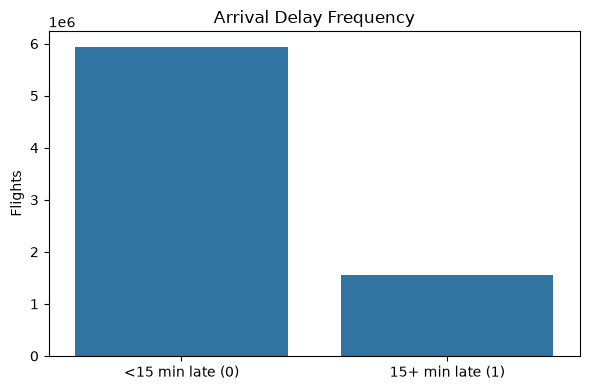

In [9]:
balance = pd.DataFrame({
    'count': flights['ArrDel15'].value_counts().sort_index(),
    'pct': (flights['ArrDel15'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(balance)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=flights, x='ArrDel15')
plt.xticks([0, 1], ['<15 min late (0)', '15+ min late (1)'])
plt.title('Arrival Delay Frequency')
plt.xlabel('')
plt.ylabel('Flights')
plt.tight_layout()
plt.show()


## Daily Delay Trends


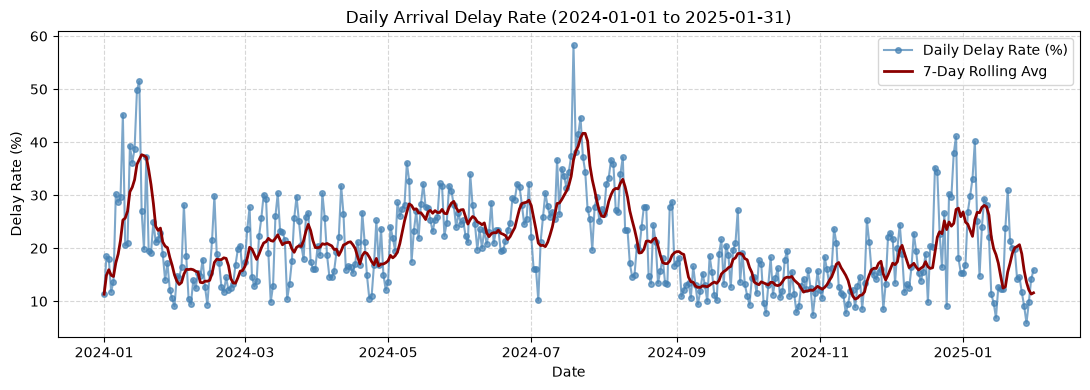

In [10]:
daily = flights.groupby('FlightDate')['ArrDel15'].mean() * 100
rolling_7d = daily.rolling(7, min_periods=1).mean()

plt.figure(figsize=(11, 4))
plt.plot(daily.index, daily.values, marker='o', markersize=4, label='Daily Delay Rate (%)', color='steelblue', alpha=0.7)
plt.plot(daily.index, rolling_7d.values, linewidth=2, label='7-Day Rolling Avg', color='darkred')
plt.title(f'Daily Arrival Delay Rate ({daily.index.min():%Y-%m-%d} to {daily.index.max():%Y-%m-%d})')
plt.xlabel('Date')
plt.ylabel('Delay Rate (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## Distance & Scheduled Duration


,count,mean,std,min,25%,50%,75%,max
Distance,7487516.0,834.6,596.7,11.0,399.0,680.0,1069.0,5095.0
CRSElapsedTime,7487516.0,147.1,72.5,6.0,94.0,130.0,178.0,859.0


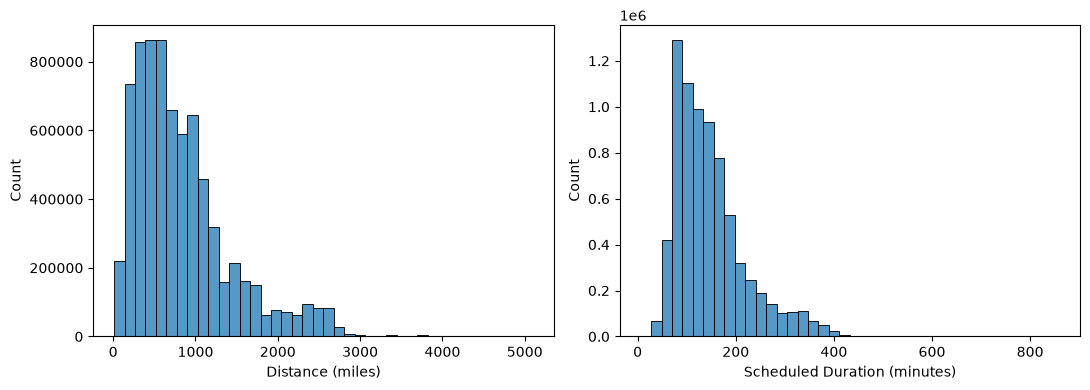

In [11]:
display(flights[['Distance', 'CRSElapsedTime']].describe().round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=flights, x='Distance', bins=40, ax=axes[0])
sns.histplot(data=flights, x='CRSElapsedTime', bins=40, ax=axes[1])
axes[0].set_xlabel('Distance (miles)')
axes[1].set_xlabel('Scheduled Duration (minutes)')
plt.tight_layout()
plt.show()


## Delays by Airline & Airport


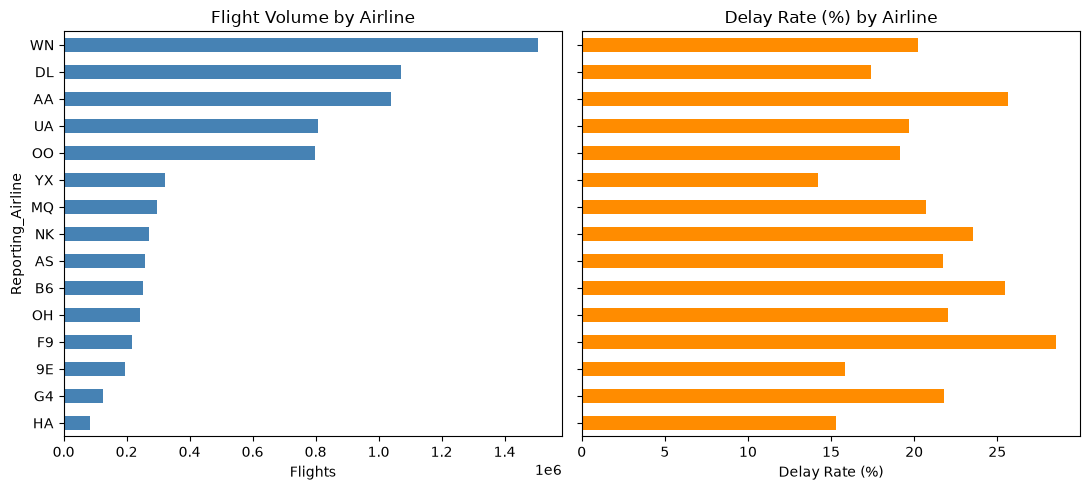

In [12]:
airlines = flights.groupby('Reporting_Airline', observed=True).agg(
    flights=('ArrDel15', 'size'),
    delayed=('ArrDel15', 'sum'),
    delay_rate=('ArrDel15', 'mean'),
    mean_distance=('Distance', 'mean')
)
airlines['delay_pct'] = (airlines['delay_rate'] * 100).round(2)

ordered = airlines.sort_values('flights')
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
ordered['flights'].plot.barh(ax=axes[0], color='steelblue')
ordered['delay_pct'].plot.barh(ax=axes[1], color='darkorange')
axes[0].set_xlabel('Flights')
axes[1].set_xlabel('Delay Rate (%)')
axes[0].set_title('Flight Volume by Airline')
axes[1].set_title('Delay Rate (%) by Airline')
plt.tight_layout()
plt.show()


In [13]:
airports = flights.groupby('Origin', observed=True).agg(flights=('ArrDel15', 'size'), delay_rate=('ArrDel15', 'mean'))
airports['delay_pct'] = (airports['delay_rate'] * 100).round(2)

display(airports.sort_values('flights', ascending=False).head(10))
print(f"Origin airports: {flights['Origin'].nunique()} | Destination airports: {flights['Dest'].nunique()}")


,flights,delay_rate,delay_pct
Origin,,,
ATL,360242,0.200665,20.07
DFW,330341,0.267175,26.72
DEN,328673,0.229292,22.93
ORD,296705,0.235149,23.51
CLT,230160,0.265176,26.52
PHX,207638,0.186175,18.62
LAX,206861,0.183447,18.34
LAS,201656,0.213229,21.32
SEA,173238,0.211172,21.12


Origin airports: 348 | Destination airports: 348


## Departure Timing


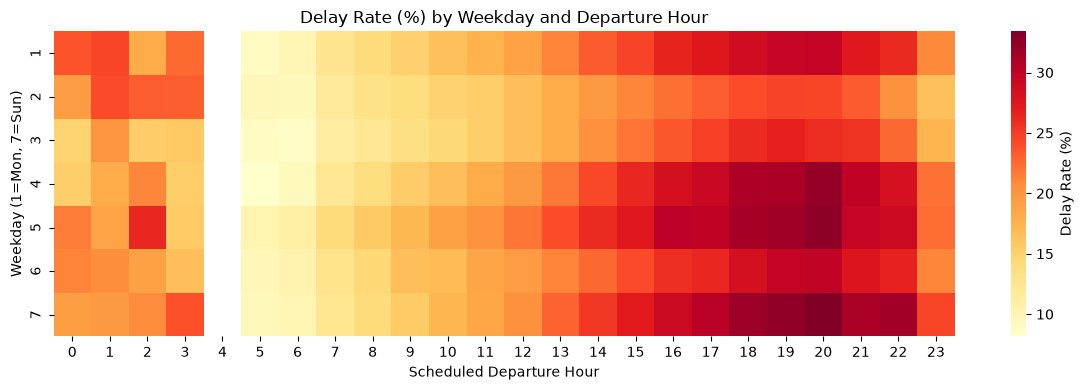

In [14]:
delay_table = flights.pivot_table(index='DayOfWeek', columns='DepHour', values='ArrDel15', aggfunc='mean', observed=True) * 100
count_table = flights.pivot_table(index='DayOfWeek', columns='DepHour', values='ArrDel15', aggfunc='count', observed=True)

plt.figure(figsize=(12, 4))
sns.heatmap(delay_table, mask=count_table.lt(100), cmap='YlOrRd', cbar_kws={'label': 'Delay Rate (%)'})
plt.title('Delay Rate (%) by Weekday and Departure Hour')
plt.xlabel('Scheduled Departure Hour')
plt.ylabel('Weekday (1=Mon, 7=Sun)')
plt.tight_layout()
plt.show()


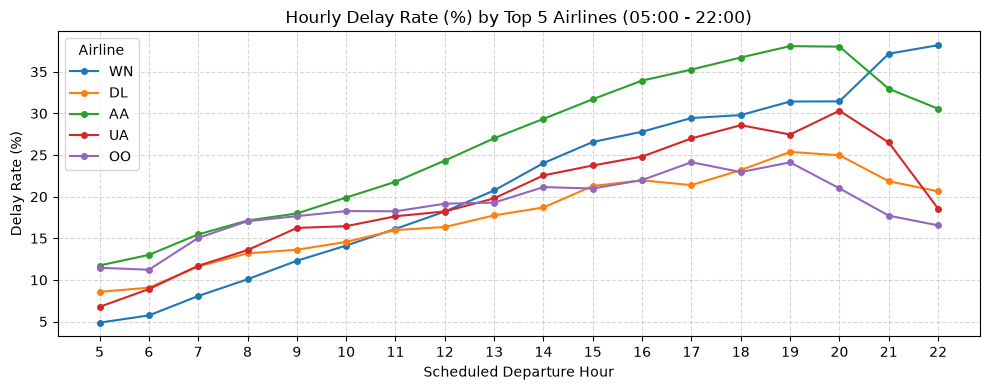

In [15]:
top5 = flights['Reporting_Airline'].value_counts().head(5).index
hourly_airline = flights[flights['Reporting_Airline'].isin(top5)].pivot_table(
    index='DepHour', columns='Reporting_Airline', values='ArrDel15', aggfunc='mean', observed=True
) * 100

plt.figure(figsize=(10, 4))
for airline in top5:
    series = hourly_airline.loc[5:22, airline]
    plt.plot(series.index, series.values, marker='o', markersize=4, label=airline)
plt.title('Hourly Delay Rate (%) by Top 5 Airlines (05:00 - 22:00)')
plt.xlabel('Scheduled Departure Hour')
plt.ylabel('Delay Rate (%)')
plt.xticks(range(5, 23))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Airline')
plt.tight_layout()
plt.show()


## Feature Correlations


,ArrDel15
DepHour,0.1563
DayOfWeek,0.0278
Distance,0.0140
CRSElapsedTime,0.0138


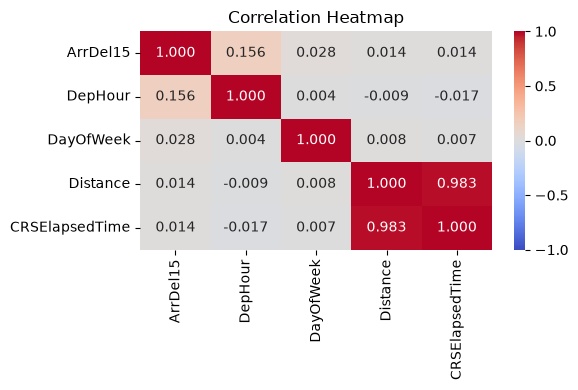

In [16]:
num_cols = ['ArrDel15', 'DepHour', 'DayOfWeek', 'Distance', 'CRSElapsedTime']
corr = flights[num_cols].corr()
display(corr[['ArrDel15']].drop(index='ArrDel15').sort_values('ArrDel15', ascending=False).round(4))

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()
